# Aggregated adaptive conformal inference

AgACI removes the one decision [ACI](aci) forces on you. Instead of picking a
learning rate, run several and let online aggregation decide, continuously, how
much to trust each.

## What it does

AgACI maintains `K` independent ACI experts, one per candidate `gamma`. At each
step every expert proposes an interval, and the two bounds are aggregated
separately:

```
lower_t = sum_k w_k^lo * lower_t^k
upper_t = sum_k w_k^up * upper_t^k
```

The weights come from an online aggregator — exponentially weighted averaging by
default — fed the **pinball loss** of each expert at its own bound: `alpha/2` for
the lower, `1 - alpha/2` for the upper. An expert whose lower bound has been well
placed gains weight on the lower bound only.

That is why the two bounds get separate weight vectors, and why an AgACI interval
is generally **asymmetric** even when every underlying expert is symmetric. The
best learning rate for tracking the bottom of a distribution is not usually the
best one for the top.

::: {.callout-note}
## Original aggregation

The original aggregation is the
Bernstein online aggregation but this implementation defaults to
exponentially weighted averaging, and the `aggregator` parameter lets you supply
your own, as a prototype instance.
:::

## Worked example

Same setup as the ACI page — one month ahead, streaming the last four years — so
the numbers are directly comparable.

In [ ]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsforecast import StatsForecast
from statsforecast.models import AutoETS

from conformalforecast import (
    AdaptiveConformalInference,
    AggregatedAdaptiveConformalInference,
    SplitConformal,
)
from conformalforecast.adapters import StatsForecastAdapter
from conformalforecast.diagnostics import agaci_state

SEASON, ALPHA = 12, 0.1
TRAIN_END = 96

# The gamma=0.2 expert below is deliberately outside the recommended range
# and warns on construction. That is the point of the table, not a surprise.
warnings.filterwarnings("ignore", message="gamma=.* is unusually large")

df = pd.read_csv("nbs/data/air_passengers.csv", parse_dates=["ds"])
panel = df["y"].to_numpy()[None, :]
train_df = df.iloc[:TRAIN_END].reset_index(drop=True)

sf = StatsForecast(models=[AutoETS(season_length=SEASON)], freq="MS", n_jobs=1)
sf.fit(train_df)
forecaster = StatsForecastAdapter(
    sf=sf, train_df=train_df, horizon=1, freq="MS", model_name="AutoETS"
)


def stream(fitted, *, online=True):
    lower, upper, covered = [], [], []
    for t in range(TRAIN_END, panel.shape[1]):
        prediction = fitted.predict(panel[:, :t])
        lo, hi = prediction.interval[0, 0, 0]
        lower.append(lo)
        upper.append(hi)
        covered.append(lo <= panel[0, t] <= hi)
        if online:
            fitted.update(prediction.point, panel[:, t : t + 1][:, None, :])
    return {"lower": np.array(lower), "upper": np.array(upper), "covered": np.array(covered)}

In [ ]:
GAMMAS = (0.001, 0.005, 0.01, 0.05, 0.1, 0.2)

agaci = AggregatedAdaptiveConformalInference(alpha=ALPHA, gammas=GAMMAS).calibrate_cv(
    forecaster, n_windows=48
)
runs = {"AgACI": stream(agaci)}

# Every expert on its own, for comparison.
for gamma in GAMMAS:
    single = AdaptiveConformalInference(alpha=ALPHA, gamma=gamma).calibrate_cv(
        forecaster, n_windows=48
    )
    runs[f"ACI gamma={gamma}"] = stream(single)

split = SplitConformal(alpha=ALPHA).calibrate_cv(forecaster, n_windows=48)
runs["split conformal"] = stream(split, online=False)

scale = panel.max()  # anything far above the data's own range is not an interval

for name, run in runs.items():
    width = (run["upper"] - run["lower"]).mean()
    shown = f"{width:8.1f}" if width < 100 * scale else f"{width:8.1e}  <- degenerate"
    print(f"{name:20s} coverage {run['covered'].mean():6.1%}   mean width {shown}")

AgACI                coverage  91.7%   mean width     80.0
ACI gamma=0.001      coverage  83.3%   mean width     74.9
ACI gamma=0.005      coverage  87.5%   mean width     78.0
ACI gamma=0.01       coverage  93.8%   mean width     83.3
ACI gamma=0.05       coverage  89.6%   mean width     88.4
ACI gamma=0.1        coverage  91.7%   mean width 2.5e+299  <- degenerate
ACI gamma=0.2        coverage  89.6%   mean width 4.6e+299  <- degenerate
split conformal      coverage  85.4%   mean width     74.7


::: {.callout-important}
## Note what happened to the largest experts

`gamma = 0.2` on its own degenerates — a run of misses drives its `alpha_t` to
zero and its interval becomes infinitely wide. AgACI contains that expert and is
unharmed, because the aggregator simply stops giving it weight. That is the
practical argument for aggregation over tuning: a bad `gamma` chosen by hand is a
production incident, while a bad `gamma` inside AgACI is a line on a weight plot.

The clipping arguments `interval_clip_lower` and `interval_clip_upper` are the
second line of defence; left at `None` they are derived at fit time from the
calibration truths.
:::

## Where the weight went

best expert, lower bound: 0.001
best expert, upper bound: 0.01


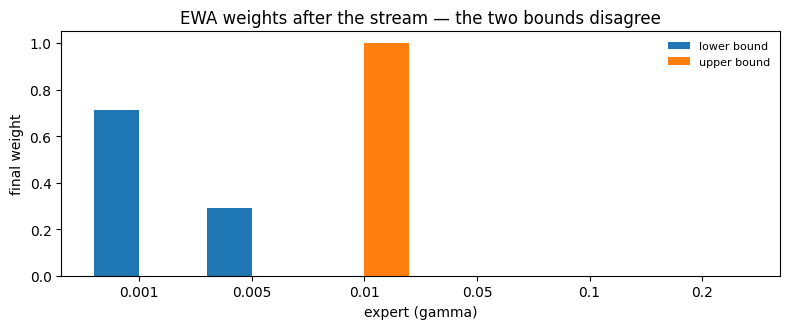

In [ ]:
state = agaci_state(agaci)
weights_lo = state["weights_lower"][:, 0, 0]
weights_up = state["weights_upper"][:, 0, 0]

x = np.arange(len(GAMMAS))
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(x - 0.2, weights_lo, width=0.4, label="lower bound", color="C0")
ax.bar(x + 0.2, weights_up, width=0.4, label="upper bound", color="C1")
ax.set_xticks(x)
ax.set_xticklabels([str(g) for g in GAMMAS])
ax.set_xlabel("expert (gamma)")
ax.set_ylabel("final weight")
ax.set_title("EWA weights after the stream — the two bounds disagree")
ax.legend(fontsize=8, frameon=False)
fig.tight_layout()

print("best expert, lower bound:", GAMMAS[state["best_expert_per_cell_lower"][0, 0]])
print("best expert, upper bound:", GAMMAS[state["best_expert_per_cell_upper"][0, 0]])

## The resulting band

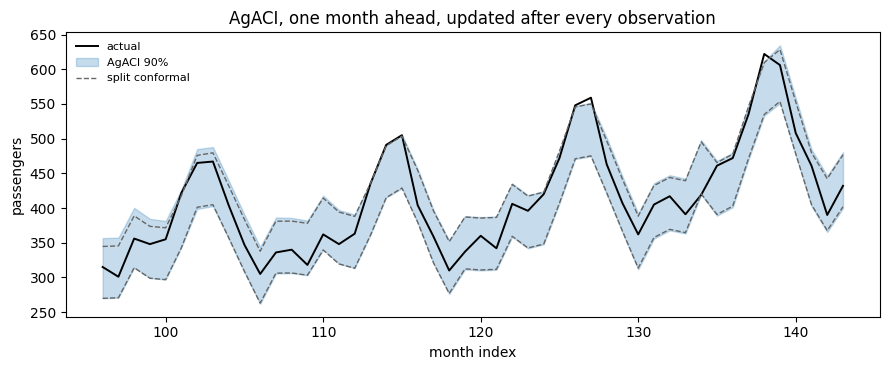

In [ ]:
months = np.arange(TRAIN_END, panel.shape[1])
truth = panel[0, TRAIN_END:]
agaci_run = runs["AgACI"]

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(months, truth, color="k", lw=1.4, label="actual")
ax.fill_between(
    months,
    agaci_run["lower"],
    agaci_run["upper"],
    color="C0",
    alpha=0.25,
    label="AgACI 90%",
)
ax.plot(
    months, runs["split conformal"]["lower"], color="0.4", lw=1, ls="--", label="split conformal"
)
ax.plot(months, runs["split conformal"]["upper"], color="0.4", lw=1, ls="--")
ax.set_xlabel("month index")
ax.set_ylabel("passengers")
ax.set_title("AgACI, one month ahead, updated after every observation")
ax.legend(fontsize=8, frameon=False, loc="upper left")
fig.tight_layout()

The AgACI band is not centred on the forecast: the two bounds are aggregated with
different weights, so they move independently. On a trending series that is a
feature — the upper bound has more work to do than the lower one.

## When not to use it

- **You have very few update steps.** Aggregation needs time to sort the experts
  out. Over a handful of observations AgACI is `K` ACIs paying rent, and plain
  [ACI](aci) with a sensible `gamma` is simpler.
- **You need a symmetric interval by contract.** AgACI's asymmetry is intrinsic.
- **Cost matters and `K` is large.** AgACI runs every expert every step. The
  expert axis is batched, so this is array work rather than a Python loop, but it
  is still `K` times the state.

## References

M. Zaffran, A. Dieuleveut, F. Olivier, Y. Goude, and J. Josse, “Adaptive Conformal Predictions for Time Series,” arXiv.org, 2022. https://arxiv.org/abs/2202.07282.

## Next

- [NexCP](nexcp) — drift handled by weighting residuals instead of targets.
- [SPCI](spci) — width that varies per step.
- [Online updating](../capabilities/online-updating) — the general loop.